# schematics.py

*Generated from `schematics.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
schematics.py -- static schematics of the He-in-WC model (illustrative).

    python3 schematics.py        # -> ../schematics/S1..S6 .png (200 dpi) + .pdf

S1_model_schema       inputs -> process -> analysis -> outputs, limitations
S2_wc_structure       WC top and side views: W, C, channel site, V_W, V_C
S3_cluster_family     the eight v3 clusters, built parent + one site
S4_binding_bookkeeping  which cells enter each binding energy
S5_search_protocol    temperature ladder of one trial + selection of the minimum
S6_diagnostics        intact / ESCAPED / trap-mutated, and how each is detected

Geometry in S2 uses the real WC lattice constants; everything else is a
cartoon and the energies in S5 are made up.
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'schematics.py'
ARGS = []              # writes ../schematics/S1..S6 (.png + .pdf)
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import os
import numpy as np
from style import *  # noqa

OUT = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..", "schematics")
os.makedirs(OUT, exist_ok=True)

In [3]:
# ===================================================================== S1
def s1():
    fig = plt.figure(figsize=(13.5, 9.2))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.text(0.5, 0.972, "He in WC: model schema", ha="center", fontsize=16, weight="bold")
    ax.text(0.5, 0.940, "every reported energy is a 0 K conjugate-gradient minimum; "
            "MD only moves the system between minima", ha="center", fontsize=10, color=INK2)

    W_ = 0.212
    X0 = [0.015 + i * (0.971 - W_) / 3 for i in range(4)]
    cols = [(X0[0], "INPUTS", "in"), (X0[1], "PROCESS (LAMMPS)", "proc"),
            (X0[2], "ANALYSIS (Python)", "ana"), (X0[3], "OUTPUTS", "out")]
    for x, t, k in cols:
        ax.text(x + W_ / 2, 0.895, t, ha="center", fontsize=11.5, weight="bold", color=EDGE[k])

    inp = [
        ("Potentials", "W–W, W–C, C–C: Juslin 2005 ABOP (tersoff/zbl)\n"
                       "W–He: Juslin & Wirth 2013 table\n"
                       "C–He: repaired table (LJ tail, 6–8 Å switch)\n"
                       "He–He: Beck + Morishita"),
        ("Structure", "hexagonal WC, a = 2.9186 Å, c = 2.8150 Å\n"
                      "8×5×8 orthogonal cells, 1280 atoms\n"
                      "periodic, volume fixed at bulk"),
        ("References", "E_bulk = −10662.4901 eV\n"
                       "He¹ at channel site: E_sol = 3.909 eV\n"
                       "E(V_W), E(V_C): empty vw1, vc1"),
        ("Search knobs", "TRIALS = 4 He placements per (X, n)\n"
                         "anneal 300 / 614.6 / 900 K, 5 ps + 5 ps\n"
                         "Berendsen τ = 0.1 ps, seed 31337"),
        ("Minimiser", "cg + line quadratic\n"
                      "ftol 1e-6 eV/Å (2-norm of all forces)"),
    ]
    proc = [
        ("in.bulk0", "relax box at 0 K\n→ wc_bulk0.restart"),
        ("in.ref", "1 He at channel site, CG\n→ res_ref.dat"),
        ("make_v3.py", "clusters = parent + 1 site\nrandom He placements\n→ cfg/, in.<series>"),
        ("in.<series> ×8", "per cfg: delete sites, add He\nCG → anneal ×3 → CG\n→ res_<series>.dat, dumps/"),
    ]
    ana = [
        ("select", "per (cluster, n): lowest E\nwith no host atom moved > 1 Å"),
        ("binding energies", "Eb(He→X), Eb(V→X), Eb_tot\npositive = bound"),
        ("flags", "ESCAPED, MUTATED, FOUND-ONCE,\nTRIALS-DIFFER, SPREAD, NVAC"),
        ("DFT priority", "YES / rec / check / no"),
        ("plot_v3.py", "→ figures_v3/"),
    ]
    out = [
        ("Interstitial (final)", "E_sol 3.91 eV (channel)\nHe–He pair −0.07 eV (c-axis)\n"
                                 "clustering ≤ 0.1 eV"),
        ("He in vacancies", "Eb(He→V_W) = 3.36 eV, holds 9 He\n"
                            "Eb(He→V_C) = 0.49 eV\n"
                            "first He in larger voids 3.4–3.85 eV"),
        ("Vacancy clusters", "W-only unbound: (V_W)₂ −0.98 / −0.36 eV\n"
                             "mixed bound: V_W V_C +0.38,\n(V_W)₂(V_C)₂ +1.69 eV;  He binds V"),
        ("Diagnostics", "median 12/16 relaxations hit the min;\ntrial spread ≤ 0.09 eV; no mutation"),
    ]

    def column(x, items, kind, top=0.87, bottom=0.285, title_fs=9.5):
        n = len(items)
        gap = 0.016
        h = (top - bottom - gap * (n - 1)) / n
        centers = []
        for i, (t, body) in enumerate(items):
            y = top - (i + 1) * h - i * gap
            box(ax, x, y, W_, h, "", kind, pad=0.004)
            ax.text(x + 0.010, y + h - 0.012, t, fontsize=title_fs, weight="bold",
                    va="top", color=EDGE[kind])
            ax.text(x + 0.010, y + h - 0.036, body, fontsize=8.2, va="top", color=INK,
                    linespacing=1.32)
            centers.append(y + h / 2)
        return centers

    column(cols[0][0], inp, "in")
    pc = column(cols[1][0], proc, "proc")
    column(cols[2][0], ana, "ana")
    column(cols[3][0], out, "out")
    for i in range(len(pc) - 1):
        hh = (0.87 - 0.285 - 0.016 * 3) / 4
        arrow(ax, (cols[1][0] + W_ * 0.85, pc[i] - hh / 2 + 0.01),
              (cols[1][0] + W_ * 0.85, pc[i + 1] + hh / 2 - 0.01),
              color=EDGE["proc"], lw=1.6, ms=12, z=5)
    for x0 in X0[:3]:
        arrow(ax, (x0 + W_ + 0.006, 0.585), (X0[1] - X0[0] + x0 - 0.006, 0.585),
              color=INK2, lw=2.2, ms=16, z=5)

    # limitations
    box(ax, 0.015, 0.02, 0.971, 0.235, "", "lim", pad=0.004)
    ax.text(0.027, 0.245, "LIMITATIONS  (what the numbers cannot tell you)", fontsize=11,
            weight="bold", color=EDGE["lim"], va="center")
    lim = [
        ("Transferability", "W–He, C–He fitted outside WC;\nerror unknown, maybe 0.1s of eV → DFT"),
        ("Host potential", "ABOP vacancy energetics in WC\nnot checked; sign of Eb(V+V)"),
        ("0 K statics", "no entropy or zero-point energy;\nmatters for 0.01–0.1 eV bonds"),
        ("Search & geometry", "one vacancy arrangement per size;\n±0.1 eV in the most crowded rows"),
        ("Cell size", "1280 atoms; image strain for\nlarge clusters → test 10×6×10"),
        ("No kinetics", "no barriers: detrapping\nE_dt = Eb + Em needs NEB"),
        ("Chemical potential", "formation energies need μ_W, μ_C;\nbinding energies do not"),
        ("Version", "decks written for LAMMPS\n29Sep2021 compute rules"),
    ]
    for i, (t, body) in enumerate(lim):
        cx = 0.027 + (i % 4) * 0.240
        cy = 0.205 - (i // 4) * 0.090
        ax.text(cx, cy, t, fontsize=9, weight="bold", color=INK, va="top")
        ax.text(cx, cy - 0.023, body, fontsize=8.2, color=INK2, va="top", linespacing=1.3)
    save(fig, os.path.join(OUT, "S1_model_schema"))

In [4]:
# ===================================================================== S2
def s2():
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6.2),
                                 gridspec_kw=dict(width_ratios=[1.45, 1.0], wspace=0.04))
    nx, ny = 4, 2
    # top view (looking down c)
    W = wc_sites(nx, ny, W_BASIS)
    Cs = wc_sites(nx, ny, C_BASIS)
    CH = wc_sites(nx, ny, CH_BASIS)
    lim_x, lim_y = (-0.6, nx * A + 0.6), (-0.6, ny * B + 0.6)
    keep = lambda P: P[(P[:, 0] > lim_x[0]) & (P[:, 0] < lim_x[1]) &
                       (P[:, 1] > lim_y[0]) & (P[:, 1] < lim_y[1])]
    W, Cs, CH = keep(W), keep(Cs), keep(CH)
    vw = np.array([2 * A, 1 * B])
    vc = np.array([1.5 * A, (1 + 1 / 6) * B])
    he = np.array([2.5 * A, (0 + 5 / 6) * B])
    # trigonal prisms (projected triangles of W) -- draw W–W triangle net
    for p in W:
        for q in W:
            d = np.linalg.norm(p - q)
            if 0.1 < d < A * 1.01:
                a1.plot([p[0], q[0]], [p[1], q[1]], color=GRID, lw=0.9, zorder=1)
    for p in W:
        if np.linalg.norm(p - vw) < 0.01:
            vacancy(a1, p)
        else:
            atom(a1, p, "W")
    for p in Cs:
        if np.linalg.norm(p - vc) < 0.01:
            vacancy(a1, p, r=0.38)
        else:
            atom(a1, p, "C")
    for p in CH:
        a1.add_patch(Circle(p, 0.16, fc="none", ec=HE_EDGE, lw=0.9, zorder=3))
    atom(a1, he, "He")
    # orthogonal cell outline
    a1.add_patch(plt.Rectangle((A, 0), A, B, fc="none", ec=INK2, lw=1.0, ls="--", zorder=5))
    a1.text(2 * A, -0.95, "orthogonal cell  a × √3a × c", fontsize=8.5, color=INK2, ha="center")
    mx = nx * A + 1.0
    lab = [(vw, "V$_W$  (W site, z = 0)", VAC_C, 8.6),
           (vc, "V$_C$  (C site, z = c/2)", VAC_C, 6.6),
           (he, "He at the empty trigonal-prismatic\nchannel site (z = c/2)\nE$_{sol}$ = 3.91 eV", HE_EDGE, 4.0),
           (CH[np.argmin(np.hypot(CH[:, 0] - 3.5 * A, CH[:, 1] - 1 / 3 * B))],
            "open circles: the other channel\nsites (one per C, same height)", INK2, 1.3)]
    for p, t, col, ty in lab:
        a1.plot([p[0], mx - 0.1], [p[1], ty], color=col, lw=0.8, zorder=6)
        a1.text(mx, ty, t, fontsize=9, color=col, va="center", weight="bold" if col == VAC_C else "normal")
    a1.set_xlim(lim_x[0], lim_x[1] + 7.5)
    a1.set_ylim(lim_y[0] - 1.3, lim_y[1] + 0.2)
    a1.set_aspect("equal")
    a1.axis("off")
    a1.set_title("top view, looking down c  (x ∥ a = %.3f Å, y ∥ b = √3a)" % A, fontsize=11)
    # side view: true projection along y of the band 0.4 < y/b < 0.9:
    #   W at y = b/2 (x = (i+1/2)a, z = 0), C at y = 2b/3 (x = ia, z = c/2),
    #   channel at y = 5b/6 (x = (i+1/2)a, z = c/2)
    nzz = 3
    for k in range(nzz + 1):
        z = k * C_LAT
        a2.axhline(z, color=GRID, lw=0.8, zorder=0)
        if k < nzz:
            a2.axhline(z + C_LAT / 2, color="#d9e6f7", lw=0.8, zorder=0)
        for i in range(0, nx + 1):
            xw = (i + 0.5) * A
            if xw < nx * A:
                if k == 1 and i == 2:
                    vacancy(a2, (xw, z))
                else:
                    atom(a2, (xw, z), "W")
            if k < nzz:
                zc = z + C_LAT / 2
                atom(a2, (i * A, zc), "C")
                if xw < nx * A:
                    if k == 1 and i == 1:
                        atom(a2, (xw, zc), "He")
                    else:
                        a2.add_patch(Circle((xw, zc), 0.16, fc="none", ec=HE_EDGE, lw=0.9, zorder=3))
    a2.add_patch(plt.Rectangle((1.5 * A - 0.5, -0.5), 1.0, nzz * C_LAT + 1.0, fc="#fff6d6",
                               ec="none", zorder=0))
    a2.text(1.5 * A, nzz * C_LAT + 0.85, "He channel along c (behind the W column, y = 5b/6)\n"
            "He–He at 2.815 Å in one channel: −0.07 eV", ha="center", fontsize=8.5, color=HE_EDGE)
    a2.annotate("", (-0.9, C_LAT), (-0.9, 2 * C_LAT), arrowprops=dict(arrowstyle="<->", color=INK2, lw=0.8))
    a2.text(-1.05, 1.5 * C_LAT, "c = %.3f Å" % C_LAT, fontsize=8.5, color=INK2, va="center",
            ha="right", rotation=90)
    a2.text(nx * A + 0.5, 0, "W layer, z = 0", va="center", fontsize=9, color=INK2)
    a2.text(nx * A + 0.5, C_LAT / 2, "C + channel layer, z = c/2", va="center", fontsize=9, color=C_EDGE)
    a2.text(nx * A + 0.5, C_LAT, "V$_W$ (dashed)", va="center", fontsize=9, color=VAC_C)
    a2.set_xlim(-1.8, nx * A + 5.8)
    a2.set_ylim(-1.0, nzz * C_LAT + 1.8)
    a2.set_aspect("equal")
    a2.axis("off")
    a2.set_title("side view: atoms with 0.4 < y/b < 0.9 projected onto x–z", fontsize=11, pad=30)
    legend_atoms(a1, 0.0, -0.04, dx=0.17)
    fig.suptitle("WC host: where W, C, the He channel site and the vacancies sit", fontsize=13,
                 weight="bold", y=0.99)
    save(fig, os.path.join(OUT, "S2_wc_structure"))

In [5]:
# ===================================================================== S3
CL = {  # (label, [sites as (x, y, species)], parent(s), He range, note)
    "vw1": ("V$_W$", [(0, 0, "W")], [], "0–12"),
    "vc1": ("V$_C$", [(0, 0, "C")], [], "0–4"),
    "vw2": ("(V$_W$)$_2$ c-axis", [(0, -0.45, "W"), (0, 0.45, "W")], ["vw1"], "0–12"),
    "vw2a": ("(V$_W$)$_2$ in-plane", [(-0.47, 0, "W"), (0.47, 0, "W")], ["vw1"], "0–12"),
    "vw3": ("(V$_W$)$_3$", [(0, -0.45, "W"), (0, 0.45, "W"), (0.8, 0, "W")], ["vw2"], "0–12"),
    "vwc": ("V$_W$V$_C$", [(-0.3, 0, "W"), (0.4, 0.05, "C")], ["vw1", "vc1"], "0–10"),
    "vwc2": ("V$_W$(V$_C$)$_2$", [(-0.3, 0, "W"), (0.4, 0.3, "C"), (0.4, -0.3, "C")], ["vwc"], "0–10"),
    "vw2c2": ("(V$_W$)$_2$(V$_C$)$_2$", [(-0.3, 0.35, "W"), (-0.3, -0.35, "W"), (0.4, 0.3, "C"),
                                           (0.4, -0.3, "C")], ["vwc2"], "0–12"),
}
POS = {"vw1": (1.0, 3.0), "vc1": (4.6, 3.0), "vw2": (0.0, 1.6), "vw2a": (1.9, 1.6),
       "vw3": (0.0, 0.2), "vwc": (3.6, 1.6), "vwc2": (3.6, 0.2), "vw2c2": (5.45, 0.2)}


def cluster_icon(ax, cx, cy, sites, scale=0.36):
    if len(sites) > 1:
        for i in range(len(sites)):
            for j in range(i + 1, len(sites)):
                p, q = sites[i], sites[j]
                if np.hypot(p[0] - q[0], p[1] - q[1]) < 1.0:
                    ax.plot([cx + p[0] * scale, cx + q[0] * scale],
                            [cy + p[1] * scale, cy + q[1] * scale], color=VAC_C, lw=1.0,
                            alpha=0.5, zorder=2)
    for x, y, sp in sites:
        r = 0.13 if sp == "W" else 0.085
        ax.add_patch(Circle((cx + x * scale, cy + y * scale), r,
                            fc="#f7dcdc" if sp == "W" else "#dde8f7", ec=VAC_C, lw=1.4,
                            ls=(0, (2.5, 1.2)), zorder=3))
        ax.text(cx + x * scale, cy + y * scale, sp, ha="center", va="center", fontsize=7,
                color=W_EDGE if sp == "W" else C_EDGE, weight="bold", zorder=4)


def s3():
    fig, ax = plt.subplots(figsize=(11, 6.8))
    ax.set_xlim(-0.9, 6.3)
    ax.set_ylim(-0.75, 4.2)
    ax.set_aspect("equal")
    ax.axis("off")
    for s, (lab, sites, par, he) in CL.items():
        cx, cy = POS[s]
        ax.add_patch(FancyBboxPatch((cx - 0.62, cy - 0.5), 1.24, 1.0,
                                    boxstyle="round,pad=0.02,rounding_size=0.08",
                                    fc="#ffffff", ec=GRID, lw=1.2, zorder=1))
        cluster_icon(ax, cx, cy + 0.08, sites)
        ax.text(cx, cy - 0.36, lab, ha="center", fontsize=9.5, weight="bold", zorder=4)
        ax.text(cx, cy + 0.42, "%s   He %s" % (s, he), ha="center", fontsize=7.5, color=INK2,
                zorder=4)
        for p in par:
            px, py = POS[p]
            add = "+W" if sum(1 for q in sites if q[2] == "W") > sum(
                1 for q in CL[p][1] if q[2] == "W") else "+C"
            if px == cx:
                p0, p1 = (px, py - 0.52), (cx, cy + 0.52)
            elif py == cy:
                p0, p1 = (px + 0.64, py), (cx - 0.64, cy)
            else:
                p0, p1 = (px + (0.35 if cx > px else -0.35), py - 0.52), (cx, cy + 0.52)
            arrow(ax, p0, p1, color=S[2] if add == "+C" else INK2, lw=1.4, ms=12)
            mx, my = (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2
            horiz = py == cy
            ax.text(mx + (0 if horiz else 0.07), my + (0.13 if horiz else 0), add, fontsize=8.5,
                    weight="bold", color=S[2] if add == "+C" else INK2, va="center",
                    ha="center" if horiz else "left", bbox=dict(fc="white", ec="none", pad=0.6))
    ax.text(-0.85, 4.15, "v3 vacancy clusters: each is its parent plus ONE site", fontsize=13,
            weight="bold", va="top")
    ax.text(-0.85, 3.9, "so the vacancy binding energy Eb(V_s → X) always compares a cluster "
            "with its own parent", fontsize=9.5, color=INK2, va="top")
    ax.text(-0.85, -0.68, "c-axis pair 2.815 Å · in-plane pair 2.919 Å · W–C neighbour 2.196 Å;  "
            "red dashed = vacated site;  4 random He placements per n ≥ 1",
            fontsize=8.5, color=INK2)
    save(fig, os.path.join(OUT, "S3_cluster_family"))

In [6]:
# ===================================================================== S4
def cell(ax, x, y, w=0.9, h=0.62, vac=(), he=0, he_out=0, label=""):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.0,rounding_size=0.04",
                                fc="#f6f6f4", ec=INK2, lw=1.0, zorder=1))
    rng = np.random.default_rng(3)
    for i in range(6):
        for j in range(4):
            px, py = x + 0.09 + i * 0.145, y + 0.09 + j * 0.148
            sp = "W" if (i + j) % 2 == 0 else "C"
            if (i, j) in vac:
                ax.add_patch(Circle((px, py), 0.05 if sp == "W" else 0.036, fc="none", ec=VAC_C, lw=1.0,
                                    ls=(0, (2, 1)), zorder=3))
            else:
                ax.add_patch(Circle((px, py), 0.045 if sp == "W" else 0.03,
                                    fc=W_C if sp == "W" else C_C, ec="none", zorder=2))
    if vac:
        vx = np.mean([x + 0.09 + i * 0.145 for i, j in vac])
        vy = np.mean([y + 0.09 + j * 0.148 for i, j in vac])
        for k in range(he):
            t = 2 * np.pi * k / max(he, 1)
            rr = 0.0 if he == 1 else 0.05
            ax.add_patch(Circle((vx + rr * np.cos(t), vy + rr * np.sin(t)), 0.032, fc=HE_C,
                                ec=HE_EDGE, lw=0.6, zorder=4))
    for k in range(he_out):
        ax.add_patch(Circle((x + 0.09 + 3.5 * 0.145, y + 0.09 + 0.5 * 0.148), 0.032, fc=HE_C,
                            ec=HE_EDGE, lw=0.6, zorder=4))
    ax.text(x + w / 2, y - 0.08, label, ha="center", va="top", fontsize=9)


def s4():
    fig, ax = plt.subplots(figsize=(13.5, 6.4))
    ax.set_xlim(0, 13.5)
    ax.set_ylim(0, 6.4)
    ax.axis("off")
    ax.text(0.15, 6.3, "Binding-energy bookkeeping: always (separated) − (together); "
            "positive = bound", fontsize=13, weight="bold", va="top")
    ax.text(0.15, 5.95, "every cell has the same 8×5×8 box; E_bulk is subtracted once for each "
            "extra cell on the 'separated' side so the atom counts match", fontsize=9.5,
            color=INK2, va="top")
    V1 = ((2, 2),)
    V2 = ((2, 2), (3, 2))
    rows = [
        (4.55, "He binding\n(adding one He)",
         [dict(vac=V1, he=2, label="E(He$_{n-1}$X)"), dict(he_out=1, label="E(He$_1$)")],
         [dict(vac=V1, he=3, label="E(He$_n$X)"), dict(label="E$_{bulk}$")],
         r"$E_b(\mathrm{He}\rightarrow X) = E(\mathrm{He}_{n-1}X) + E(\mathrm{He}_1) - "
         r"E(\mathrm{He}_nX) - E_{bulk}$"),
        (2.75, "vacancy binding\n(adding one site s)",
         [dict(vac=V1, he=3, label="E(He$_n$X$'$)  parent"), dict(vac=((3, 2),), label="E(V$_s$)")],
         [dict(vac=V2, he=3, label="E(He$_n$X)"), dict(label="E$_{bulk}$")],
         r"$E_b(V_s\rightarrow X) = E(\mathrm{He}_nX') + E(V_s) - E(\mathrm{He}_nX) - E_{bulk}$"),
        (0.95, "total binding\n(everything apart)",
         [dict(vac=((2, 2),), label="n$_W$ × E(V$_W$)"), dict(vac=((3, 2),), label="n$_C$ × E(V$_C$)"),
          dict(he_out=1, label="n × E(He$_1$)")],
         [dict(vac=V2, he=3, label="E(He$_n$X)"), dict(label="(n$_W$+n$_C$+n−1) E$_{bulk}$")],
         r"$E_b^{tot} = n_W E(V_W) + n_C E(V_C) + n\,E(\mathrm{He}_1) - E(\mathrm{He}_nX) - "
         r"(n_W{+}n_C{+}n{-}1)E_{bulk}$"),
    ]
    for y, title, left, right, eq in rows:
        ax.text(0.15, y + 0.31, title, fontsize=10.5, weight="bold", va="center", color=S[1])
        x = 2.3
        ax.text(x + (len(left) * 1.17 - 0.12) / 2, y + 0.82, "separated", fontsize=8.5,
                ha="center", color=INK2, style="italic")
        for i, c in enumerate(left):
            cell(ax, x, y, **c)
            x += 1.05
            if i < len(left) - 1:
                ax.text(x - 0.08, y + 0.31, "+", fontsize=15, ha="center", va="center")
                x += 0.12
        ax.text(x + 0.25, y + 0.31, "−", fontsize=20, ha="center", va="center", color=VAC_C)
        x += 0.55
        ax.text(x + (len(right) * 1.17 - 0.12) / 2, y + 0.82, "together (+ bulk to balance)",
                fontsize=8.5, ha="center", color=INK2, style="italic")
        ax.text(x - 0.12, y + 0.31, "[", fontsize=30, ha="center", va="center", color=INK2)
        for i, c in enumerate(right):
            cell(ax, x, y, **c)
            x += 1.05
            if i < len(right) - 1:
                ax.text(x - 0.08, y + 0.31, "+", fontsize=15, ha="center", va="center")
                x += 0.12
        ax.text(x - 0.05, y + 0.31, "]", fontsize=30, ha="center", va="center", color=INK2)
        ax.text(x + 0.25, y + 0.31, eq, fontsize=10.5, va="center")
    ax.text(0.15, 0.12, "solution energy: E_sol = E(He$_1$) − E$_{bulk}$  (isolated He atom = 0 "
            "for these pair potentials)        pair interaction: E_int(d) = E(pair) + E$_{bulk}$ − "
            "2E(He$_1$)  (positive = repulsive)", fontsize=9, color=INK2)
    legend_atoms(ax, 0.745, 0.585, dx=0.06, fs=8.5)
    save(fig, os.path.join(OUT, "S4_binding_bookkeeping"))

In [7]:
# ===================================================================== S5
def ladder():
    """time (ps) and T (K) of one trial: CG, then 3 x (hold 5 ps, ramp 5 ps, CG)."""
    t, T, marks = [0.0], [0.0], [(0.0, "CG")]
    t0 = 0.6
    for Tk in (300.0, 614.6, 900.0):
        t += [t0, t0, t0 + 5]
        T += [0.0, Tk, Tk]
        tq = np.linspace(t0 + 5, t0 + 10, 30)
        Tq = Tk + (1.0 - Tk) * (tq - t0 - 5) / 5.0   # temp/berendsen ramps the target linearly
        t += list(tq)
        T += list(Tq)
        t += [t0 + 10, t0 + 10.6]
        T += [0.0, 0.0]
        marks.append((t0 + 10.3, "CG"))
        t0 += 11.2
    return np.array(t), np.array(T), marks


def s5():
    fig = plt.figure(figsize=(12, 7.2))
    g = fig.add_gridspec(2, 2, height_ratios=[1, 1.05], width_ratios=[1.6, 1], hspace=0.42,
                         wspace=0.22)
    a = fig.add_subplot(g[0, :])
    t, T, marks = ladder()
    a.plot(t, T, color=S[1], lw=2)
    a.fill_between(t, 0, T, color=S[1], alpha=0.08)
    for k, (tm, lab) in enumerate(marks):
        a.axvline(tm, color=S[0], lw=1, ls=":")
        a.plot(tm, 20, "D", color=S[0], ms=8, zorder=5)
        a.text(tm, 1010, "relax %d\n(cycle %d)" % (k + 1, k + 1), ha="center", fontsize=8.5,
               color=S[0])
    t0 = 0.6
    for Tk in (300.0, 614.6, 900.0):
        a.text(t0 + 2.5, Tk + 25, "hold %g K, 5 ps" % Tk, ha="center", fontsize=8.5, color=INK2,
               va="bottom")
        t0 += 11.2
    a.annotate("quench: target ramps\nlinearly to 1 K (5 ps)", (19.3, 320), (19.8, 760), ha="center",
               fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-|>", color=INK2, lw=0.8))
    a.set(xlabel="MD time (ps; 1 fs timestep)", ylabel="thermostat target T (K)", ylim=(-30, 1180),
          xlim=(-0.8, t.max() + 1.6))
    a.set_title("one trial = 4 relaxations: as placed, then after each anneal "
                "(each step continues from the last)", fontsize=11, loc="left")
    for sp in ("top", "right"):
        a.spines[sp].set_visible(False)

    # selection panel (made-up energies)
    b = fig.add_subplot(g[1, 0])
    rng = np.random.default_rng(7)
    best = 0.0
    E = {1: [1.9, 0.62, 0.0, 0.0], 2: [2.4, 0.95, 0.31, 0.31], 3: [1.3, 0.0, 0.0, 0.0],
         4: [3.1, 1.4, 0.62, 0.0]}
    mut = (4, 3)
    for tr in range(1, 5):
        for cy in range(1, 5):
            e = E[tr][cy - 1]
            x = cy + (tr - 2.5) * 0.12
            if (tr, cy) == mut:
                b.plot(x, -0.35, "X", color=VAC_C, ms=10, zorder=5)
                b.annotate("host atom moved > 1 Å:\nexcluded (MUTATED flag\nif it is the lowest)",
                           (x, -0.35), (x + 0.12, 1.15), fontsize=8, color=VAC_C,
                           arrowprops=dict(arrowstyle="-", color=VAC_C, lw=0.7))
                continue
            b.plot(x, e, MARKERS[tr - 1], color=S[tr - 1], ms=7, mec="white", mew=0.6,
                   label="trial %d" % tr if cy == 1 else None, zorder=4)
        b.plot([cy + (tr - 2.5) * 0.12 for cy in range(1, 5) if (tr, cy) != mut],
               [E[tr][cy - 1] for cy in range(1, 5) if (tr, cy) != mut], color=S[tr - 1],
               lw=0.8, alpha=0.5)
    b.axhline(0, color=S[2], lw=1.2, ls="--")
    b.text(4.45, 0.04, "reported\nminimum", color=S[2], fontsize=8.5, va="bottom", ha="right")
    b.text(2.05, 2.55, "hits = 6 of 16 within 1 meV\nTRIALS-DIFFER: trial 2 stuck 0.31 eV\n"
           "above the minimum (> 0.10 eV)", fontsize=8.5, color=INK2, va="top")
    b.set(xticks=[1, 2, 3, 4], xticklabels=["as placed", "after 300 K", "after 614.6 K",
                                            "after 900 K"],
          ylabel="E − E$_{min}$ (eV, made up)", ylim=(-0.6, 3.4))
    b.legend(fontsize=8, frameon=False, loc="upper right", ncol=2)
    b.set_title("pick the lowest intact minimum over 4 trials × 4 relaxations", fontsize=11,
                loc="left")
    for sp in ("top", "right"):
        b.spines[sp].set_visible(False)

    # landscape cartoon
    c = fig.add_subplot(g[1, 1])
    x = np.linspace(0, 10, 600)
    y = landscape(x)
    c.plot(x, y, color=INK, lw=1.6)
    L = lambda q: float(landscape(np.array([q]))[0])
    c.plot(6.45, L(6.45), "o", color=S[3], ms=8, mec=INK, mew=0.6, zorder=5)
    c.annotate("", (6.73, L(6.73) + 0.08), (6.47, L(6.45) + 0.12),
               arrowprops=dict(arrowstyle="-|>", color=S[3], lw=1.2))
    c.text(6.73, L(6.73) - 0.42, "1", ha="center", fontsize=9, weight="bold", color="#a87000")
    c.plot(6.73, L(6.73), "o", color=S[3], ms=9, mec=INK, mew=0.6, zorder=5)
    c.annotate("", (7.93, L(7.93) + 0.1), (6.78, L(6.73) + 0.1),
               arrowprops=dict(arrowstyle="-|>", color=S[1], lw=1.4, connectionstyle="arc3,rad=-0.6"))
    c.text(8.45, L(7.93) + 0.05, "2", ha="center", fontsize=9, weight="bold", color=S[1])
    c.plot(7.93, L(7.93), "o", color=S[1], ms=9, mec=INK, mew=0.6, zorder=5)
    c.annotate("", (4.62, L(4.56) + 0.12), (7.88, L(7.93) + 0.12),
               arrowprops=dict(arrowstyle="-|>", color=VAC_C, lw=1.4, connectionstyle="arc3,rad=0.55"))
    c.text(4.15, L(4.56) + 0.1, "3", ha="center", fontsize=9, weight="bold", color=VAC_C)
    c.text(0.25, 3.55, "1  placed, CG to the nearest minimum\n2  300 K anneal hops a small barrier\n"
           "3  900 K anneal crosses a large one", fontsize=8, va="top", color=INK, linespacing=1.4)
    c.plot(2.02, L(2.02), "o", color=INK2, ms=7, mfc="white", mec=INK2, zorder=5)
    c.text(2.02, L(2.02) - 0.5, "another trial\nstarts here", ha="center", fontsize=7.5, color=INK2)
    xg = x[np.argmin(y)]
    c.plot(xg, y.min(), "*", color=S[2], ms=16, mec=INK, mew=0.6, zorder=6)
    c.text(xg, y.min() - 0.45, "global min", ha="center", fontsize=8.5, color=S[2])
    c.set(xticks=[], yticks=[], xlabel="He arrangement (configuration space)", ylabel="E (0 K)",
          ylim=(y.min() - 0.9, y.max() + 1.35))
    c.set_title("why anneal: escape local minima", fontsize=11, loc="left")
    for sp in ("top", "right"):
        c.spines[sp].set_visible(False)
    fig.suptitle("Configuration search (v3): random placement, anneal ladder, 0 K selection",
                 fontsize=13, weight="bold", y=0.995)
    save(fig, os.path.join(OUT, "S5_search_protocol"))


MARKERS = ["o", "s", "^", "D", "v"]


def landscape(x):
    return (0.18 * (x - 6.6) ** 2 * 0.25 + 0.75 * np.sin(2.3 * x) + 0.35 * np.sin(5.1 * x + 1)
            + 0.9 * np.exp(-((x - 3.2) / 0.5) ** 2) + 1.2 * np.exp(-((x - 7.0) / 0.35) ** 2))

In [8]:
# ===================================================================== S6
def s6():
    fig, axs = plt.subplots(1, 3, figsize=(13, 5.0))
    titles = [("intact", S[2], "kin = n  and  nfar = 0\n→ used"),
              ("ESCAPED", S[1], "kin < n\n→ dropped (not a He$_n$X energy)"),
              ("trap mutation", VAC_C, "nfar > 0 (a host atom moved > 1 Å)\n→ excluded; flagged if lower")]
    DX, DY = 1.4, 1.25
    for ax, (t, col, note) in zip(axs, titles):
        ax.set_xlim(-4.7, 4.7)
        ax.set_ylim(-4.6, 4.3)
        ax.set_aspect("equal")
        ax.axis("off")
        for j in range(-3, 4):
            for i in range(-4, 5):
                p = np.array([i * DX + (DX / 2 if j % 2 else 0), j * DY])
                if np.hypot(*p) > 4.3:
                    continue
                isW = j % 2 == 0
                if abs(p[0]) < 1e-6 and abs(p[1]) < 1e-6:
                    vacancy(ax, p, r=0.36)
                    continue
                if t == "trap mutation" and abs(p[0] - DX) < 1e-6 and abs(p[1]) < 1e-6:
                    ax.add_patch(Circle(p, 0.36, fc="none", ec=INK2, lw=0.9, ls=":"))
                    q = np.array([1.95, 0.6])
                    atom(ax, q, "W", r=0.36, z=5)
                    ax.text(q[0] + 0.15, q[1] + 0.45, "> 1 Å", fontsize=9.5, color=VAC_C,
                            weight="bold", zorder=8)
                    continue
                atom(ax, p, "W" if isW else "C", r=0.36 if isW else 0.22)
        Rc = 2.6
        ax.add_patch(Circle((0, 0), Rc, fc="none", ec=S[0], lw=1.5, ls="--", zorder=6))
        he = [np.array([0.22 * np.cos(a), 0.22 * np.sin(a)]) for a in
              np.linspace(0, 2 * np.pi, 4, endpoint=False) + 0.5]
        if t == "ESCAPED":
            he[0] = np.array([3.5, -0.62])
            arrow(ax, (0.2, -0.15), (3.3, -0.58), color=S[1], lw=1.4, ms=11, z=7)
        if t == "trap mutation":
            he = [p * 2.2 for p in he]
            arrow(ax, (1.45, 0.05), (1.8, 0.45), color=VAC_C, lw=1.3, ms=9, z=7)
        for p in he:
            atom(ax, p, "He", r=0.19, z=7)
        ax.set_title(t, fontsize=12.5, weight="bold", color=col, pad=2)
        ax.text(0, -3.95, note, ha="center", fontsize=9.5, color=INK, va="top")
    fig.suptitle("What every relaxation is checked for (res_*.dat columns kin, nfar, rg)",
                 fontsize=13, weight="bold", y=0.86)
    fig.text(0.5, 0.1, "dashed blue circle = 'core' region: farthest vacant site + 2.2 Å "
             "(kin counts He inside it);  nfar counts W/C atoms > 1 Å from their lattice site;  "
             "rg − rg0 > 1.5 Å flags SPREAD", ha="center", fontsize=9, color=INK2)
    legend_atoms(axs[0], 0.08, -0.02, dx=0.22)
    save(fig, os.path.join(OUT, "S6_diagnostics"))

In [9]:
if __name__ == "__main__":
    s1(); s2(); s3(); s4(); s5(); s6()

wrote ../schematics/S1_model_schema.{png,pdf}


wrote ../schematics/S2_wc_structure.{png,pdf}


wrote ../schematics/S3_cluster_family.{png,pdf}


wrote ../schematics/S4_binding_bookkeeping.{png,pdf}


wrote ../schematics/S5_search_protocol.{png,pdf}


wrote ../schematics/S6_diagnostics.{png,pdf}


## Outputs

In [10]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


S1_model_schema.png


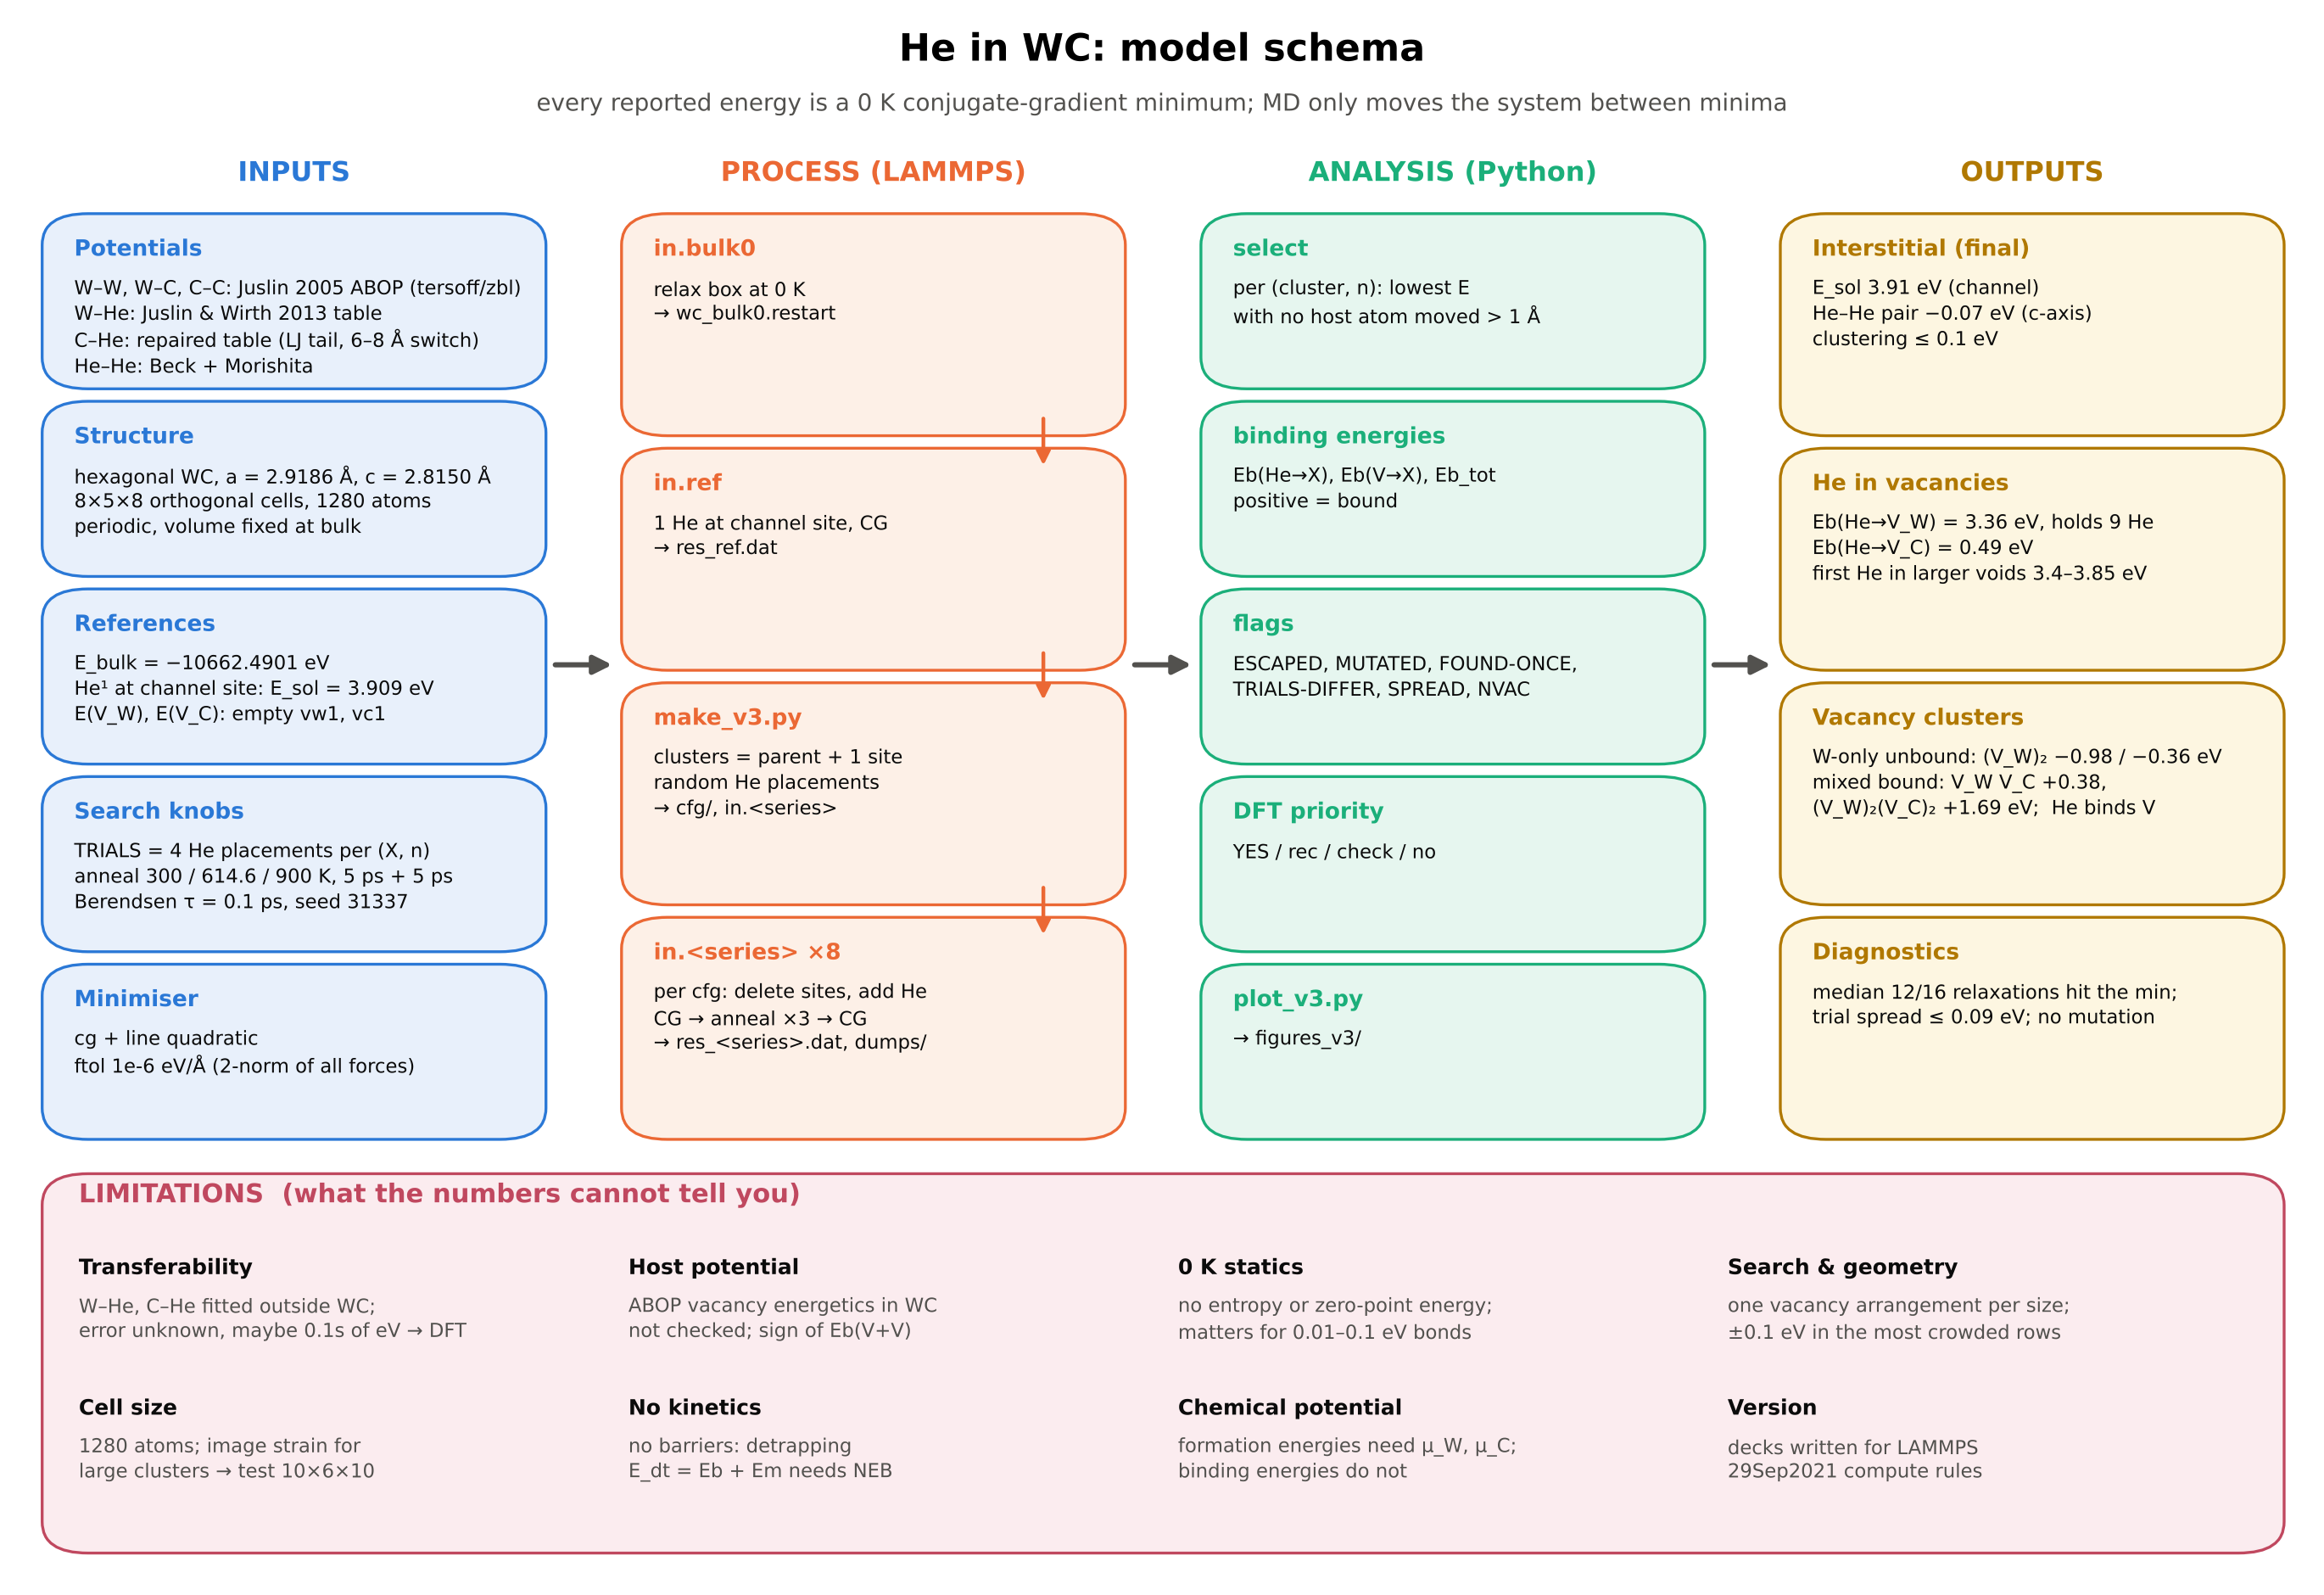

S2_wc_structure.png


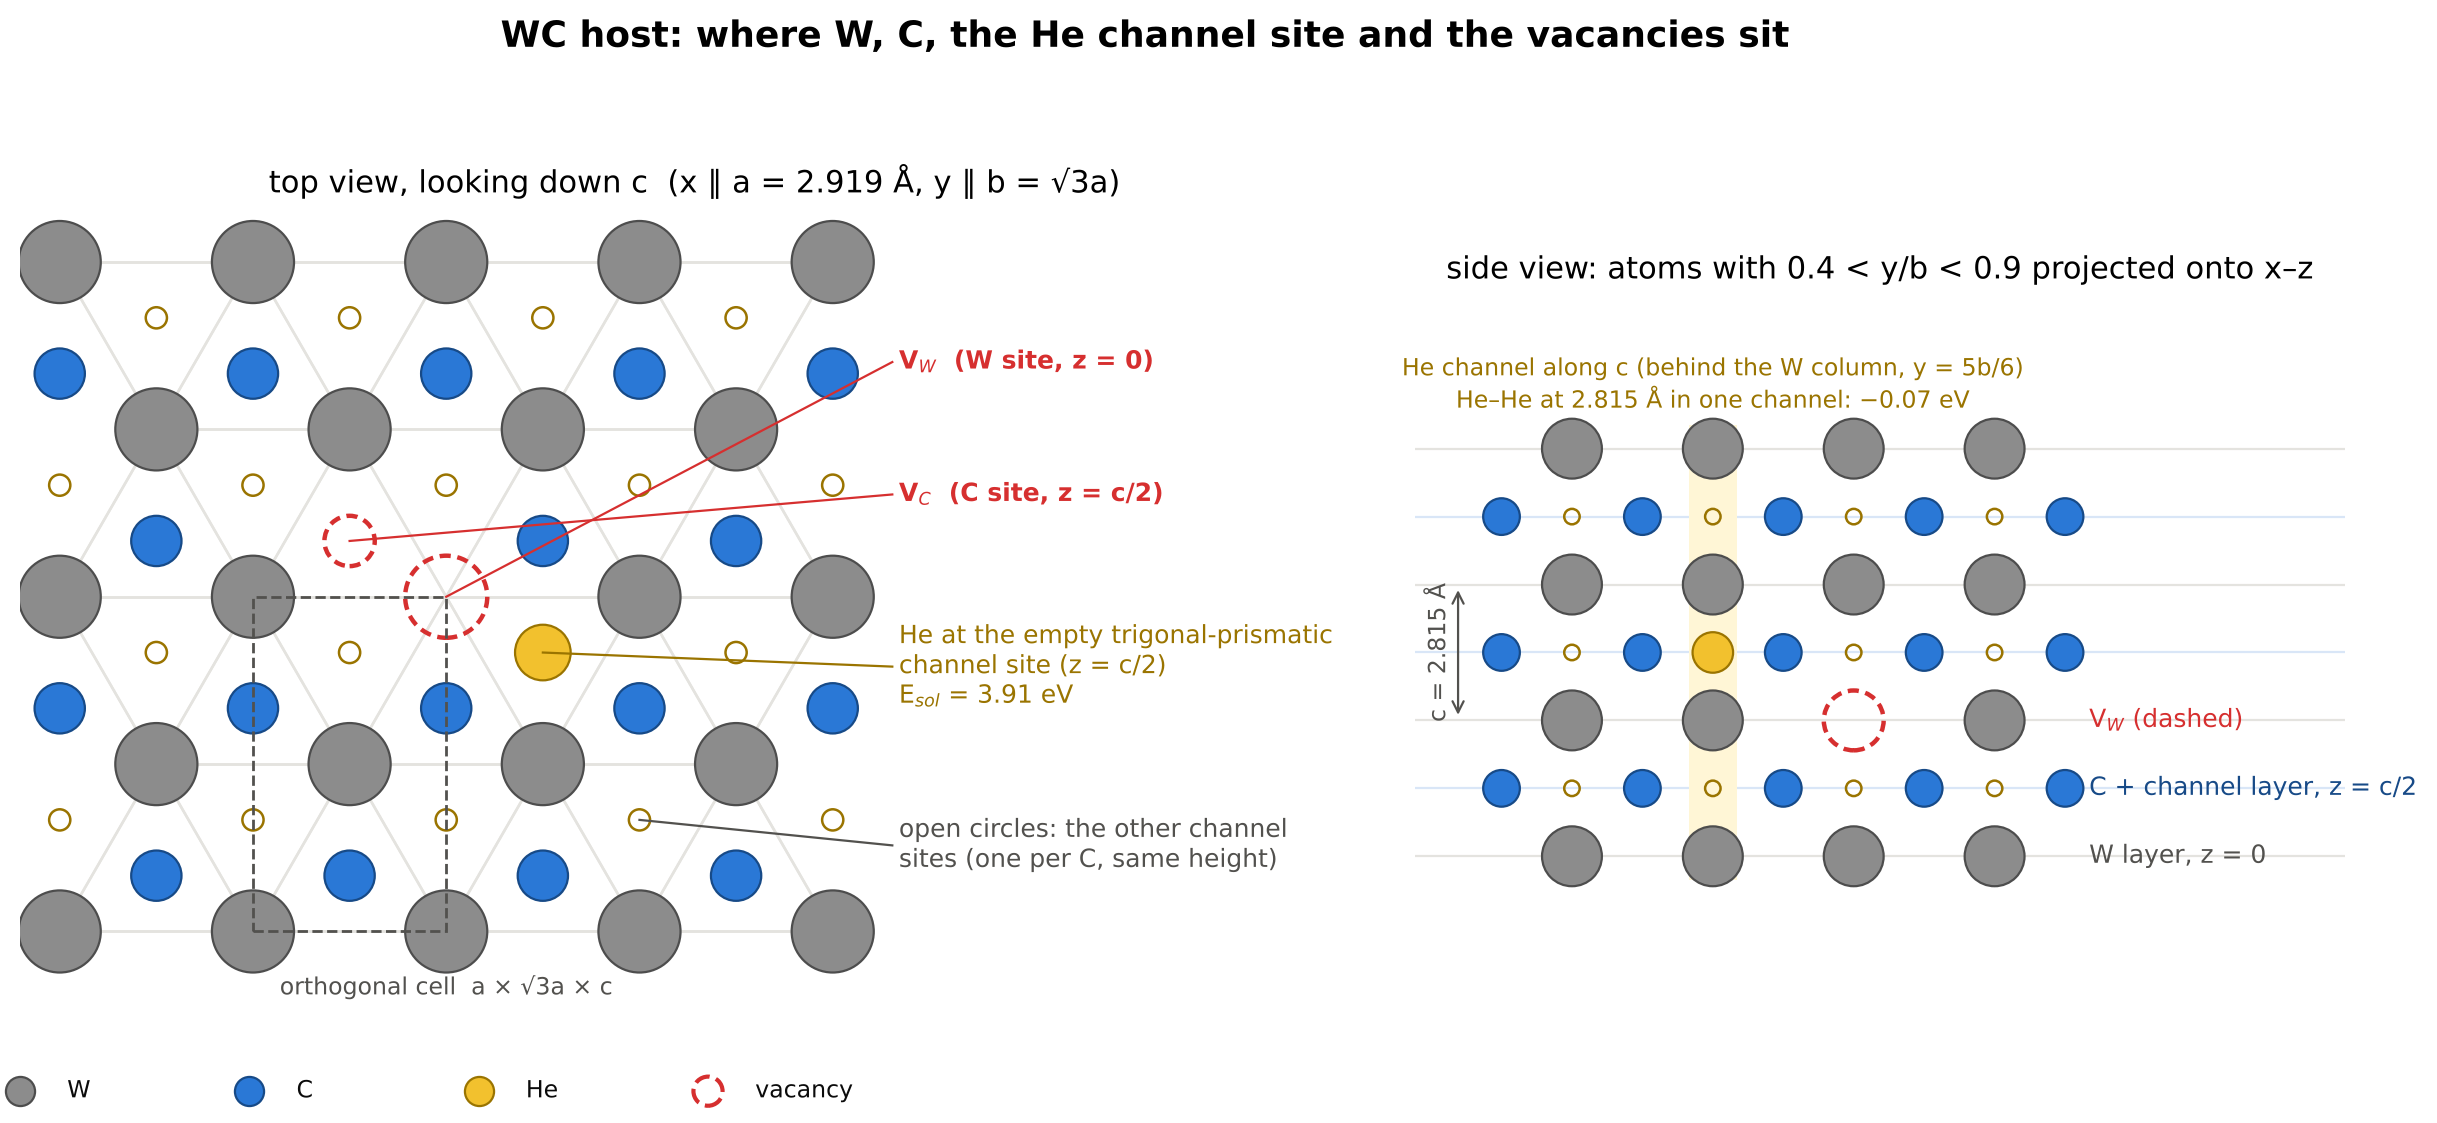

S3_cluster_family.png


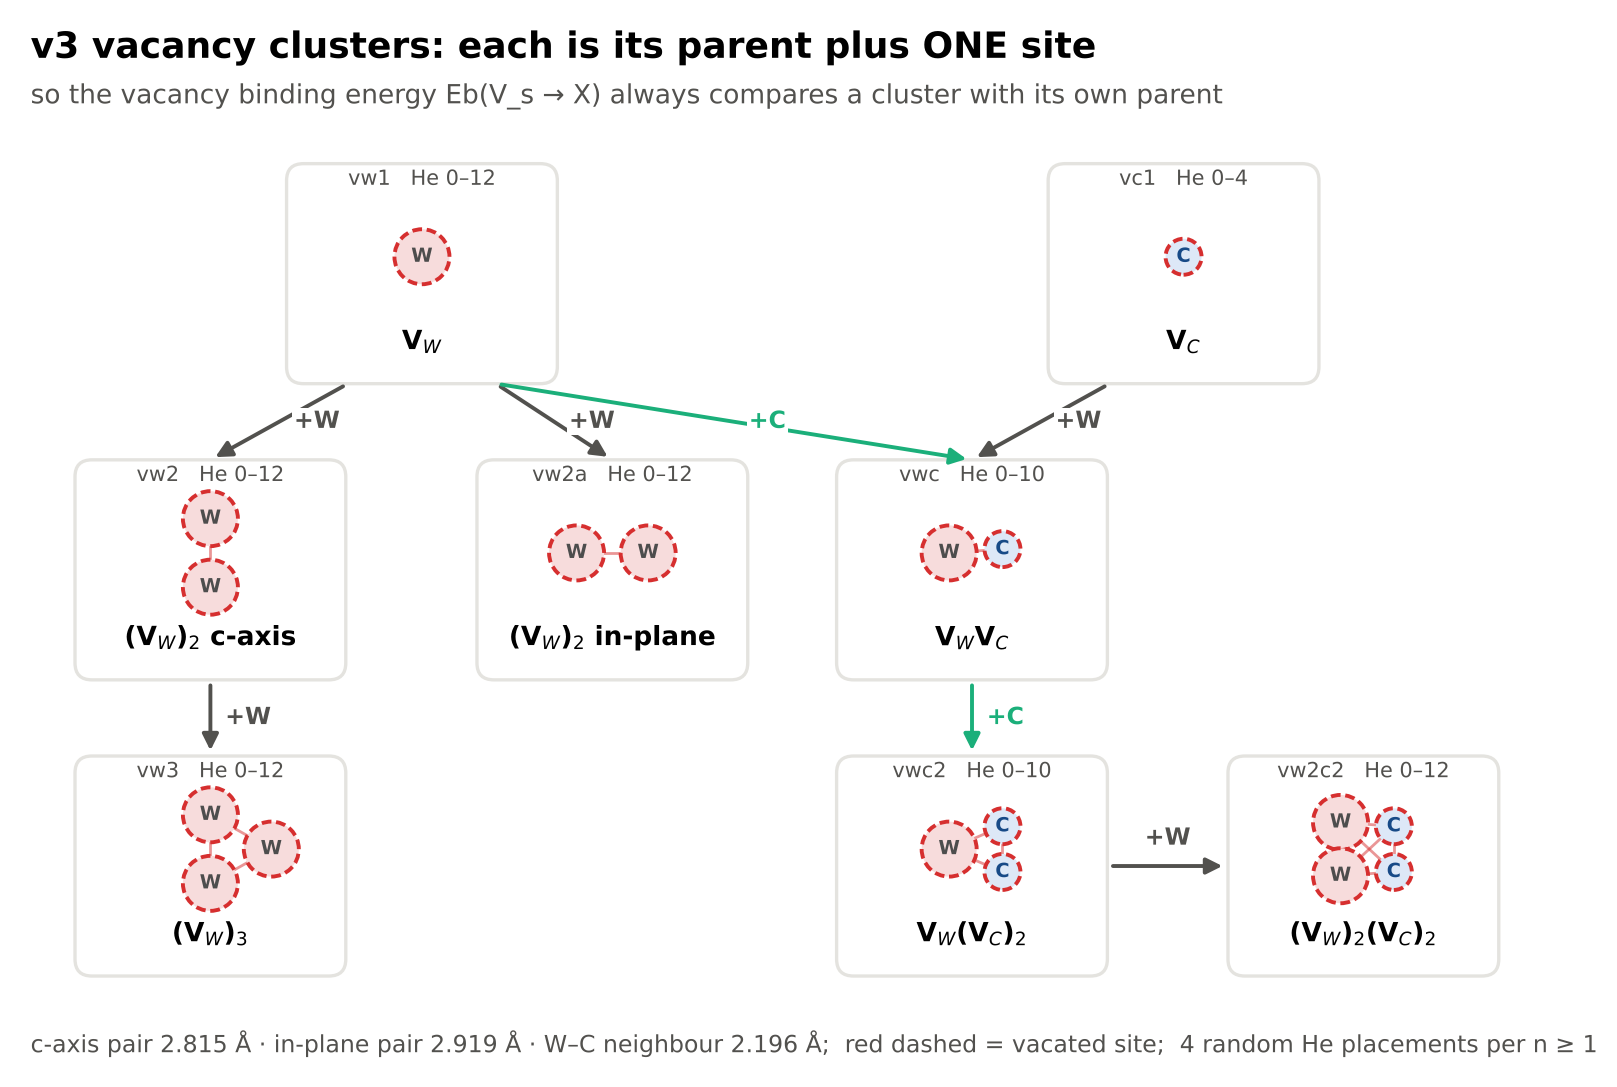

S4_binding_bookkeeping.png


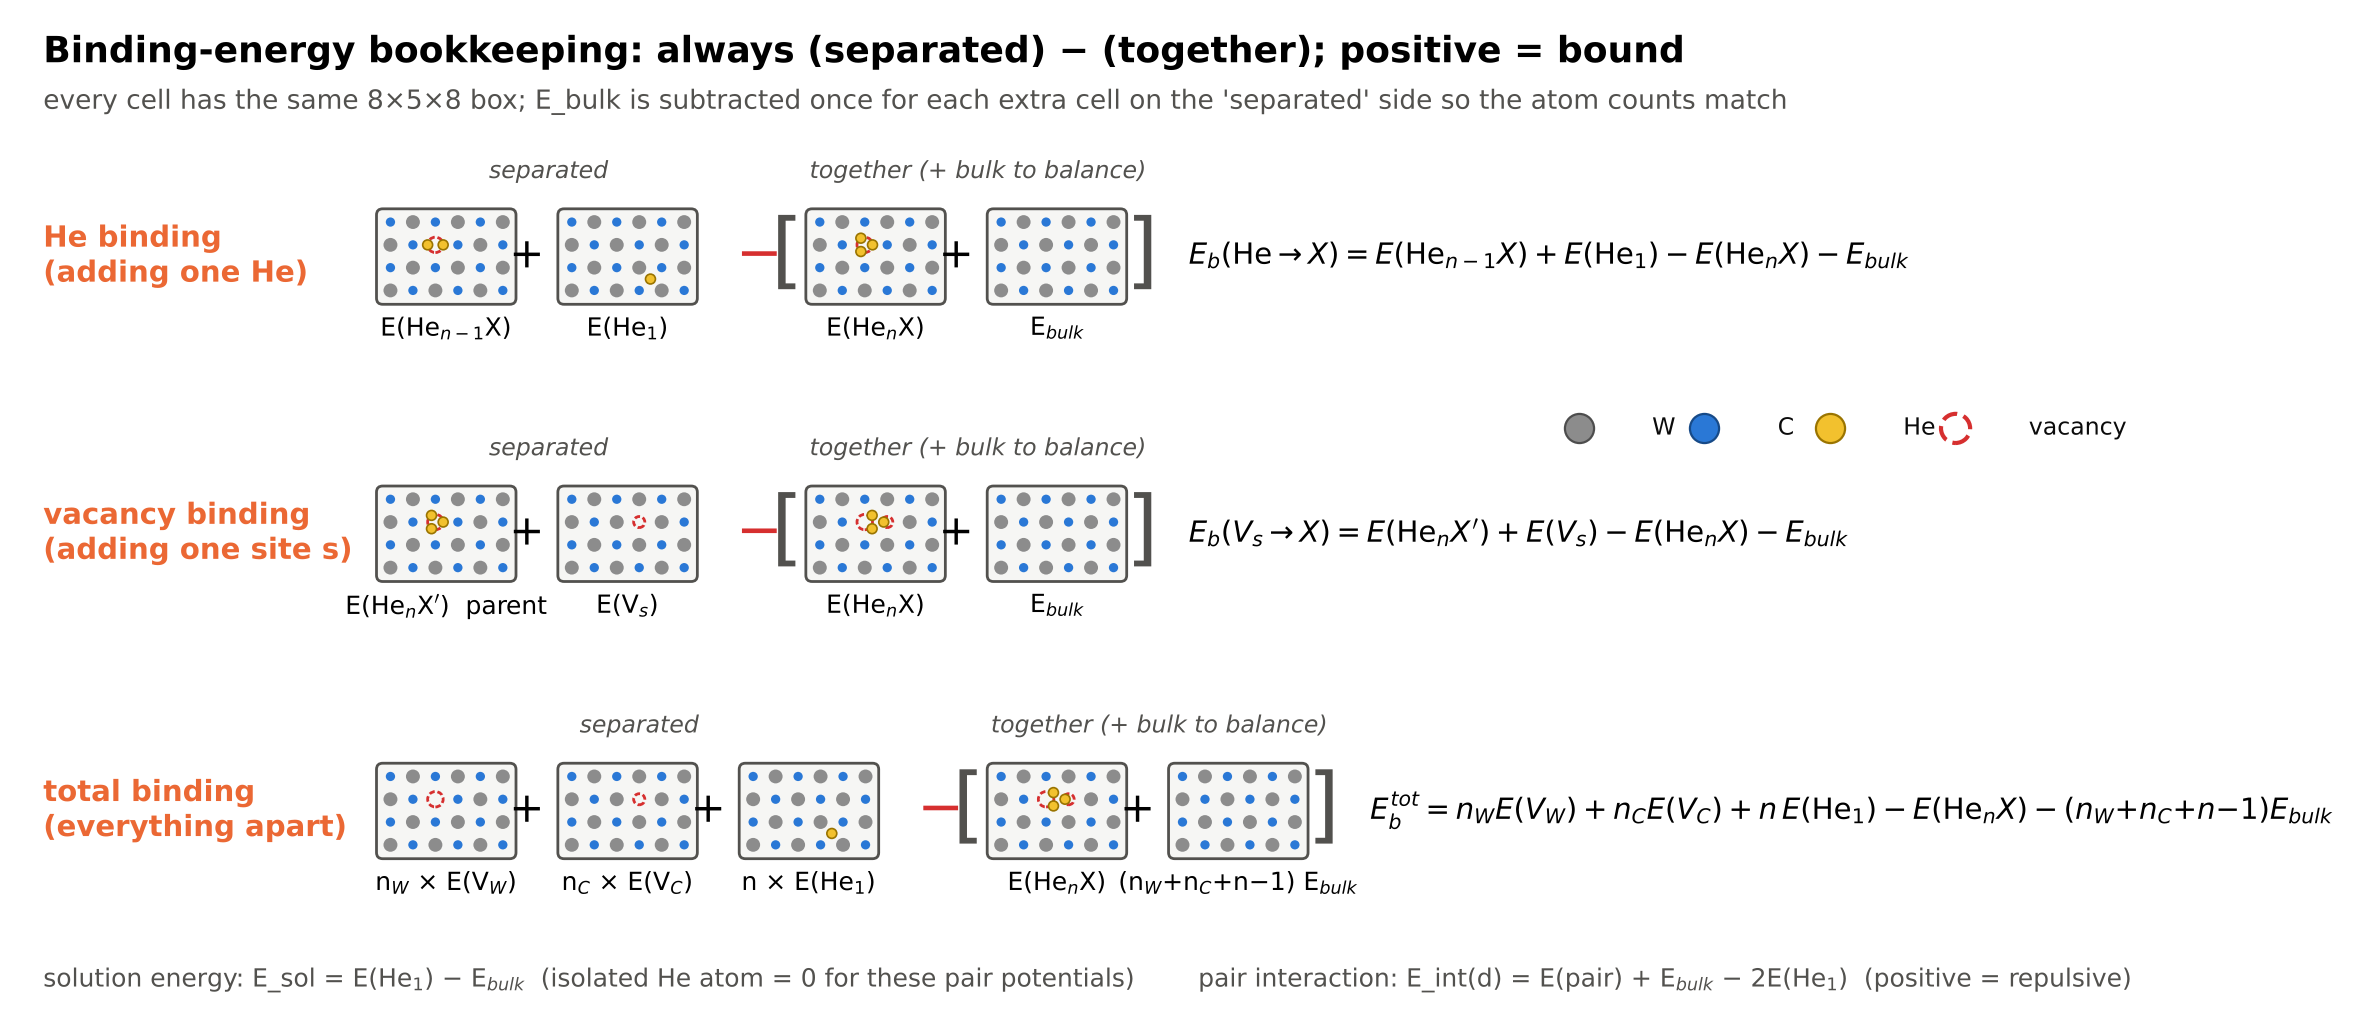

S5_search_protocol.png


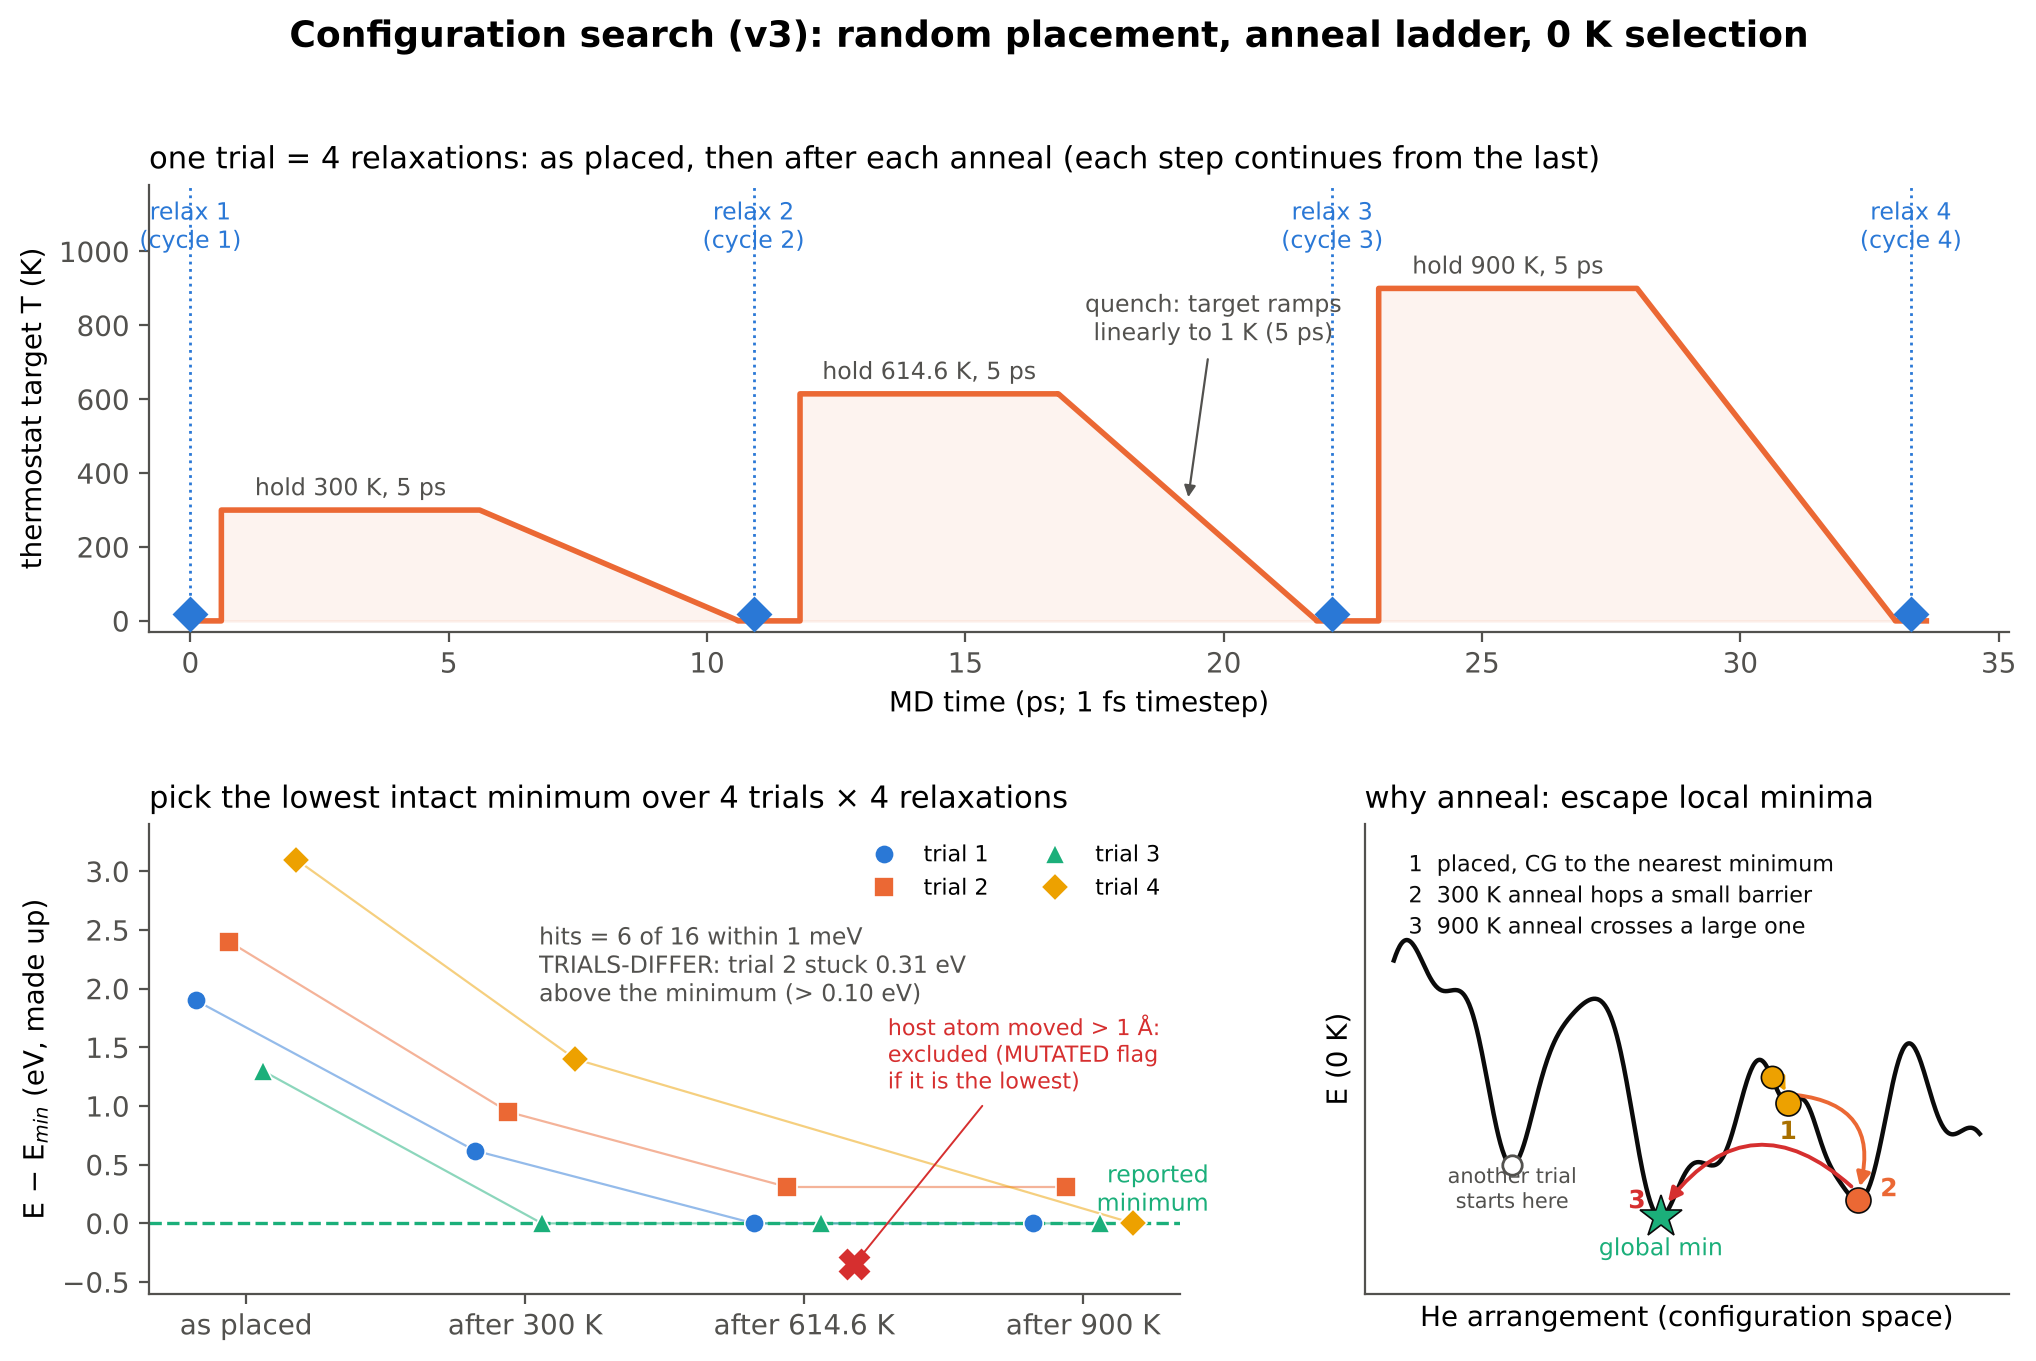

S6_diagnostics.png


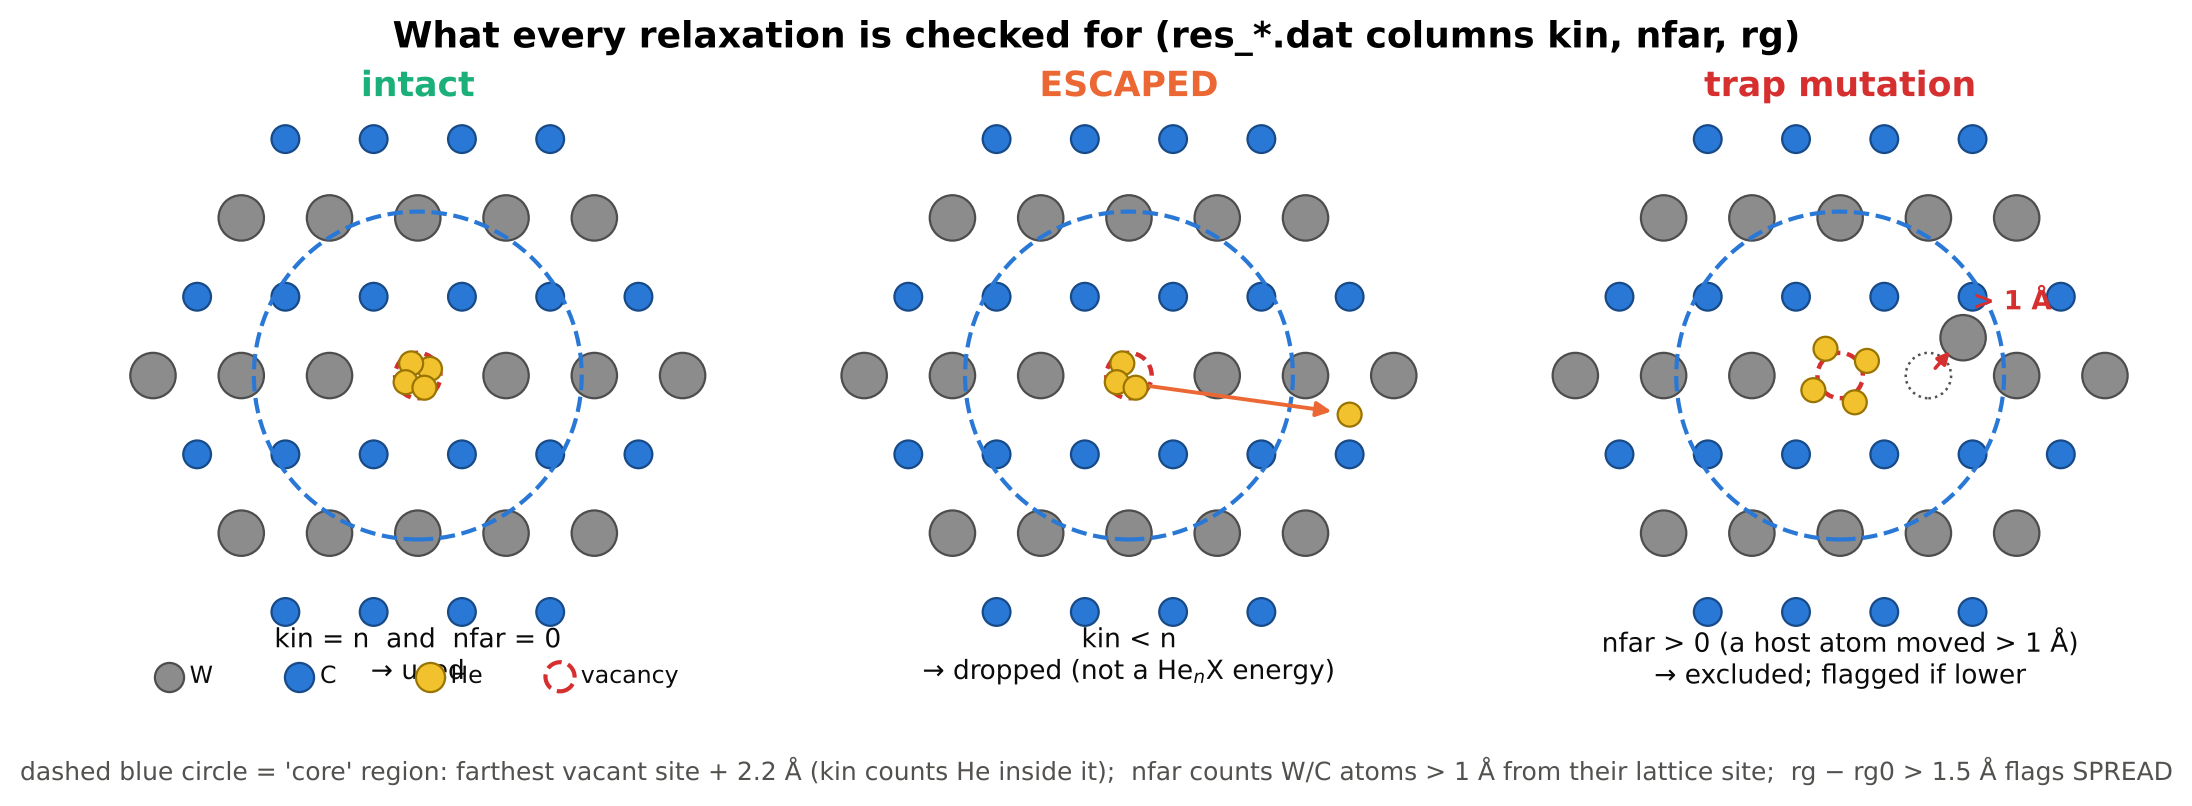

In [11]:
show(os.path.join('..', 'schematics'), ['S1_model_schema.png', 'S2_wc_structure.png', 'S3_cluster_family.png', 'S4_binding_bookkeeping.png', 'S5_search_protocol.png', 'S6_diagnostics.png'])